In [6]:
import pandas as pd

df = pd.read_csv("student_feedback_sentiments.csv")

print("Dataset Shape:", df.shape)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'student_feedback_sentiments.csv'

In [7]:
import os

os.listdir("/content")

['.config', 'student_feedback_sentiment.csv', 'sample_data']

In [9]:
df = pd.read_csv("/content/student_feedback_sentiment.csv")

In [10]:
import pandas as pd

df = pd.read_csv("student_feedback_sentiment.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (724, 4)


,text,category,sentiment_score,sentiment
0,all these are good,examination,1,positive
1,Satisfactory,library_facilities,1,positive
2,very good.,library_facilities,1,positive
3,"it is quite good , depends upon teacher and th...",teaching,1,positive
4,Yes,labwork,1,positive


In [11]:
print("Dataset Shape:", df.shape)

Dataset Shape: (724, 4)


In [12]:
df.head()

,text,category,sentiment_score,sentiment
0,all these are good,examination,1,positive
1,Satisfactory,library_facilities,1,positive
2,very good.,library_facilities,1,positive
3,"it is quite good , depends upon teacher and th...",teaching,1,positive
4,Yes,labwork,1,positive


In [14]:
df.columns

Index(['text', 'category', 'sentiment_score', 'sentiment'], dtype='object')

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 724 entries, 0 to 723
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   text             724 non-null    object
 1   category         724 non-null    object
 2   sentiment_score  724 non-null    int64 
 3   sentiment        724 non-null    object
dtypes: int64(1), object(3)
memory usage: 22.8+ KB


In [16]:
df.isnull().sum()

,0
text,0
category,0
sentiment_score,0
sentiment,0


In [17]:
df["sentiment"].value_counts()

,count
sentiment,
positive,451
negative,139
neutral,134


In [18]:
print(df.columns.tolist())

['text', 'category', 'sentiment_score', 'sentiment']


In [19]:
df.head(10)

,text,category,sentiment_score,sentiment
0,all these are good,examination,1,positive
1,Satisfactory,library_facilities,1,positive
2,very good.,library_facilities,1,positive
3,"it is quite good , depends upon teacher and th...",teaching,1,positive
4,Yes,labwork,1,positive
5,Our university has lot of extracurricular goin...,extracurricular,1,positive
6,excellent,teaching,1,positive
7,"Teaching is excellent,but lecture delivery is ...",teaching,1,positive
8,I like the question pattern,examination,1,positive
9,ALL PRACTICAL WORK IS GOOD,labwork,1,positive


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 724 entries, 0 to 723
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   text             724 non-null    object
 1   category         724 non-null    object
 2   sentiment_score  724 non-null    int64 
 3   sentiment        724 non-null    object
dtypes: int64(1), object(3)
memory usage: 22.8+ KB


In [21]:
df["sentiment"].value_counts()

,count
sentiment,
positive,451
negative,139
neutral,134


In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df["sentiment"].unique()

array(['positive', 'negative', 'neutral'], dtype=object)

In [24]:
# Select only the required columns
df = df[["text", "sentiment"]]

# Remove any rows with missing values
df = df.dropna()

# Remove duplicate records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("Final Dataset Shape:", df.shape)

df.head()

Final Dataset Shape: (639, 2)


,text,sentiment
0,all these are good,positive
1,Satisfactory,positive
2,very good.,positive
3,"it is quite good , depends upon teacher and th...",positive
4,Yes,positive


In [25]:
df["sentiment"].value_counts()

,count
sentiment,
positive,379
negative,134
neutral,126


In [26]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["sentiment"]

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [48]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 511
Testing samples: 128


In [49]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [31]:
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (511, 805)
Testing shape: (128, 805)


In [50]:
from sklearn.linear_model import LogisticRegression

In [51]:
model = LogisticRegression(class_weight="balanced", max_iter=1000)

model.fit(X_train_tfidf, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [52]:
y_pred = model.predict(X_test_tfidf)

In [53]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
590,positive,positive
387,positive,positive
381,positive,positive
602,positive,positive
47,positive,positive
214,positive,positive
524,negative,negative
475,positive,positive
292,positive,positive
272,positive,positive


In [55]:
from sklearn.metrics import accuracy_score, classification_report

In [56]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 59.375 %


In [57]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.43      0.44      0.44        27
     neutral       0.22      0.16      0.19        25
    positive       0.73      0.79      0.76        76

    accuracy                           0.59       128
   macro avg       0.46      0.46      0.46       128
weighted avg       0.57      0.59      0.58       128



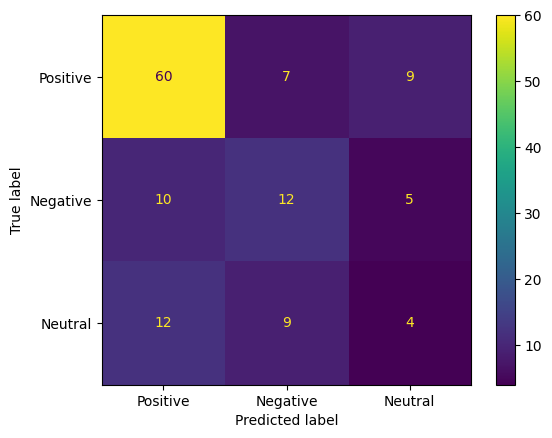

In [58]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["positive", "negative", "neutral"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Positive", "Negative", "Neutral"]
)

display.plot()
plt.show()

In [59]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.43      0.44      0.44        27
     neutral       0.22      0.16      0.19        25
    positive       0.73      0.79      0.76        76

    accuracy                           0.59       128
   macro avg       0.46      0.46      0.46       128
weighted avg       0.57      0.59      0.58       128



In [60]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_tfidf, y_train)

baseline_pred = baseline.predict(X_test_tfidf)

print("Baseline Accuracy:", accuracy_score(y_test, baseline_pred) * 100)
print("Our Model Accuracy:", accuracy_score(y_test, y_pred) * 100)

Baseline Accuracy: 59.375
Our Model Accuracy: 59.375


In [61]:
print("Current dataset:", df.shape)
print("X records:", len(X))
print("Y records:", len(y))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Current dataset: (639, 2)
X records: 639
Y records: 639
Training records: 511
Testing records: 128


In [63]:
original_df = pd.read_csv("/content/student_feedback_sentiment.csv")

print("Original rows:", len(original_df))
print("Missing values in required columns:")
print(original_df[["text", "sentiment"]].isnull().sum())

print("Duplicate rows:", original_df[["text", "sentiment"]].duplicated().sum())

Original rows: 724
Missing values in required columns:
text         0
sentiment    0
dtype: int64
Duplicate rows: 85


In [64]:
ngram_range=(1, 2)

In [65]:
new_feedback = [
    "The teacher explains everything very clearly.",
    "The lectures are boring and confusing.",
    "The class starts at 9 AM."
]

new_feedback_tfidf = tfidf.transform(new_feedback)

predictions = model.predict(new_feedback_tfidf)

for feedback, prediction in zip(new_feedback, predictions):
    print("Feedback:", feedback)
    print("Predicted Sentiment:", prediction)
    print()

Feedback: The teacher explains everything very clearly.
Predicted Sentiment: positive

Feedback: The lectures are boring and confusing.
Predicted Sentiment: neutral

Feedback: The class starts at 9 AM.
Predicted Sentiment: positive



In [66]:
df.to_csv("dataset.csv", index=False)

In [67]:
from google.colab import files
files.download("dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>